# Onboarding Intervention Decision Lab
**A five-minute portfolio readout · NON_CANONICAL_DEMO**

One completed synthetic experiment, from randomized assignment to a frozen result and comparison with known synthetic truth. **Not Exness data or an Exness internal process.**

This notebook reads the recorded demo at `outputs/demo_slice1/NON_CANONICAL_DEMO/`. It generates no cohort and makes no new approval or unblinding decision. Code cells are folded by default; saved outputs provide the readout.

*Offline execution from the repository root:*  
`.venv/bin/python notebooks/execute_demo_notebook.py`  
The unchanged pinned environment has no Jupyter/plotting dependencies; the helper runs ordinary Python cells and records self-contained SVG/HTML outputs.


In [1]:
from pathlib import Path
from datetime import datetime
import csv
import hashlib
import html
import json
import math
import sys

REPO = Path(".") if Path("contracts").is_dir() else Path("..")
assert (REPO / "contracts").is_dir(), "Start from the repository root or notebooks/."
sys.path.insert(0, str(REPO / "src"))
from oidl.adapters.environment import verify_execution_environment
from oidl.adapters.release import load_release
verify_execution_environment((REPO / "requirements-dev.lock").read_bytes())
verified_contracts = load_release(REPO / "contracts")
DEMO = REPO / "outputs/demo_slice1/NON_CANONICAL_DEMO"
LABEL = "NON_CANONICAL_DEMO"
RUN_ID = LABEL + "_SLICE1_V1"
inventory = json.loads((DEMO / "demo_file_inventory.json").read_text())
assert inventory["demonstration"] == LABEL
members = {m["path"]: m for m in inventory["members"]}
checked_paths = set()
read_log = []

def checked_path(relative):
    # Only already-released public material; never custody payloads or seed inputs.
    assert relative.startswith(("public/", "exposure_registry/"))
    assert relative in members
    path = DEMO / relative
    assert not path.is_symlink() and path.is_file()
    if relative not in checked_paths:
        assert path.stat().st_size == members[relative]["bytes"]
        with path.open("rb") as stream:
            assert hashlib.file_digest(stream, "sha256").hexdigest() == members[relative]["sha256"]
        checked_paths.add(relative)
    read_log.append(relative)
    return path

def record(relative):
    value = json.loads(checked_path(relative).read_text())
    assert value["run_id"] == RUN_ID
    return value

def table_rows(name):
    with checked_path("public/analyst/payload/" + name + ".tsv").open() as stream:
        for row in csv.DictReader(stream, delimiter="\t"):
            yield {k: json.loads(v) for k, v in row.items()}

INK, MUTED, BLUE, GRAY, TEAL, GRID = "#172d40", "#617385", "#266a98", "#8a98a6", "#258277", "#dce4eb"

def text(x, y, value, size=14, fill=INK, weight="normal", anchor="start"):
    return (f'<text x="{x}" y="{y}" font-size="{size}" fill="{fill}" '
            f'font-weight="{weight}" text-anchor="{anchor}">{html.escape(str(value))}</text>')

def line(x1, y1, x2, y2, color=GRID, width=1, dash=""):
    return (f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" '
            f'stroke="{color}" stroke-width="{width}" stroke-dasharray="{dash}"/>')

def box(x, y, w, h, fill="#f5f8fa"):
    return f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="5" fill="{fill}" stroke="{GRID}"/>'

def dot(x, y, color=BLUE, radius=5):
    return f'<circle cx="{x}" cy="{y}" r="{radius}" fill="{color}"/>'

def show_svg(parts, height, title, description):
    svg = (f'<svg xmlns="http://www.w3.org/2000/svg" width="1000" height="{height}" '
           f'viewBox="0 0 1000 {height}" role="img" style="max-width:100%;height:auto;'
           'font-family:Arial,sans-serif;background:white">'
           f'<title>{html.escape(title)}</title><desc>{html.escape(description)}</desc>'
           + "".join(parts) + "</svg>")
    display({"image/svg+xml": svg, "text/plain": f"{LABEL}: {title}. {description}"}, raw=True)

def show_table(headers, rows, caption=""):
    content = ('<div style="font:14px/1.5 Arial,sans-serif;color:#172d40;max-width:1000px">'
               f'<p>{html.escape(caption)}</p>' if caption else
               '<div style="font:14px/1.5 Arial,sans-serif;color:#172d40;max-width:1000px">')
    content += '<table style="border-collapse:collapse;width:100%"><thead><tr>'
    content += "".join(f'<th style="text-align:left;padding:7px 12px;border-bottom:2px solid #dce4eb">'
                       f'{html.escape(str(h))}</th>' for h in headers) + "</tr></thead><tbody>"
    for row in rows:
        content += "<tr>" + "".join(
            f'<td style="padding:6px 12px;border-bottom:1px solid #edf1f5">'
            f'{html.escape(str(v))}</td>' for v in row) + "</tr>"
    content += "</tbody></table></div>"
    display({"text/html": content, "text/plain": "\n".join(" | ".join(map(str,r)) for r in [headers,*rows])}, raw=True)

primary_record = record("public/primary_itt_result.json")
primary = primary_record["payload"]["deterministic_result"]
audit_record = record("public/randomization_audit.json")
audit = audit_record["payload"]["deterministic_result"]
counts = audit["design_counts"]
assert primary["ResearchSpec_hash"] == verified_contracts.research_spec_hash
assert (counts["screened_n"], primary["N"], primary["n1"], primary["n0"]) == (55000,50000,25000,25000)
assert primary_record["payload"]["claim_status"] == "CALCULATION_ONLY_NO_CAUSAL_CLAIM"
display({"text/plain": "NON_CANONICAL_DEMO · recorded artifacts verified · pinned CPython 3.12.3 · read-only presentation"}, raw=True)


NON_CANONICAL_DEMO · recorded artifacts verified · pinned CPython 3.12.3 · read-only presentation

## 1. Business question
**Does assignment to proactive neutral onboarding assistance increase the probability that an eligible new client makes a first successful deposit within 168 hours of registration?**

The intervention offers onboarding/KYC help without deposit or trading pressure. The estimand is **randomized, assignment-level intention-to-treat (ITT)**: assignment to assistance versus control, within the frozen eligible population. This is a synthetic portfolio case, not a description of Exness operations.


## 2. Experiment design
Eligibility is established at the recorded landmark before assignment. Randomization is exactly 1:1 within 16 blocks defined by KYC friction, period and regime.

Assignment defines the comparison because reach and successful contact occur after randomization and can depend on client characteristics. Keeping every randomized person in their assigned arm preserves the intended ITT comparison.


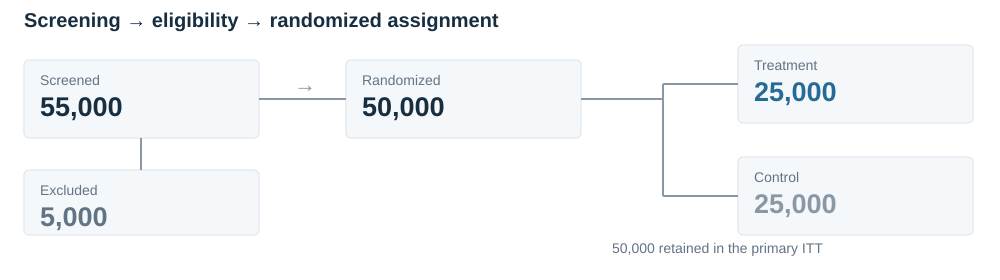

In [2]:
parts = [text(24, 27, "Screening → eligibility → randomized assignment", 20, weight="bold")]
for x,y,w,h,title,value,color in [
    (24,60,235,78,"Screened",counts["screened_n"],INK),
    (346,60,235,78,"Randomized",counts["randomized_n"],INK),
    (24,170,235,65,"Excluded",counts["excluded_n"],MUTED),
    (738,45,235,78,"Treatment",counts["treatment_n"],BLUE),
    (738,157,235,78,"Control",counts["control_n"],GRAY)]:
    parts += [box(x,y,w,h),text(x+16,y+25,title,14,MUTED),text(x+16,y+56,f"{value:,}",27,color,"bold")]
parts += [line(259,99,346,99,GRAY,2),text(294,92,"→",22,GRAY),
          line(141,138,141,170,GRAY,2),line(581,99,663,99,GRAY,2),
          line(663,84,663,196,GRAY,2),line(663,84,738,84,GRAY,2),line(663,196,738,196,GRAY,2),
          text(612,253,"50,000 retained in the primary ITT",14,MUTED)]
show_svg(parts,280,"Experiment population","55,000 screened; 5,000 excluded; 50,000 randomized, 25,000 per arm.")


## 3. Customer journey
Registration → onboarding/KYC → assistance or BAU → funding initiation → qualifying settlement → primary outcome.

The examples below are the first recorded person matching each illustrative pattern. They show observed chronology, not individual causal effects or pattern prevalence. Times are elapsed hours from each person's registration; **Y** is copied from the recorded primary outcome at 168 hours.


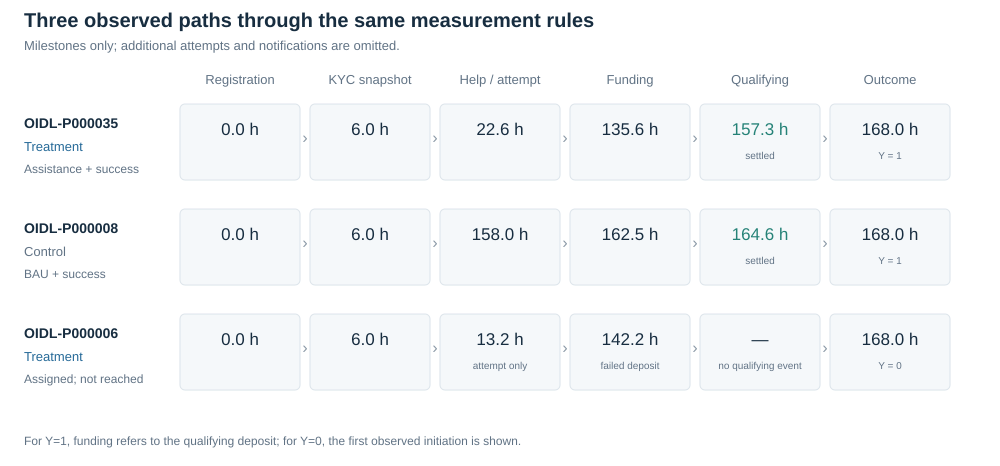

In [3]:
arms = {r["person_id"]: r["assigned_onboarding_assistance"] for r in table_rows("randomization")}
outcomes = {r["person_id"]: r for r in table_rows("primary_outcomes")}
journeys, group = {}, []
for event in table_rows("observed_event_log"):
    if event["event_type"] == "REGISTRATION_CONFIRMATION":
        group = []
    group.append(event)
    if event["event_type"] != "PERSON_PATH_SUMMARY":
        continue
    pid, state = event["person_id"], event["details"]
    outcome = outcomes[pid]
    y = outcome["first_successful_deposit_by_registration_168h"]
    pattern = ("Assistance + success" if arms[pid] == 1 and state["help_accepted"] and y == 1 else
               "BAU + success" if arms[pid] == 0 and state["BAU_help"] and y == 1 else
               "Assigned; not reached" if arms[pid] == 1 and state["attempted"] and not state["reached"] and y == 0 else None)
    if pattern and pattern not in journeys:
        registration = next(e["event_ts"] for e in group if e["event_type"] == "REGISTRATION_CONFIRMATION")
        kyc = next(e["event_ts"] for e in group if e["event_type"] == "KYC_STATE_NOTIFICATION")
        deposits = [e["details"] for e in group if e["event_type"] == "DEPOSIT"]
        qualifying = outcome["qualifying_success_ts"]
        selected = (next(d for d in deposits if d["qualifying_success_ts"] == qualifying)
                    if qualifying else min(deposits, key=lambda d: d["initiation_ts"], default=None))
        help_or_attempt = (state["first_substantive_help_ts"] or state["initial_attempt_ts"])
        journeys[pattern] = dict(pid=pid, arm=arms[pid], y=y, registration=registration,
            clocks=[registration,kyc,help_or_attempt,
                    selected["initiation_ts"] if selected else None,qualifying,outcome["horizon_ts"]],
            deposit_status=selected["final_status"] if selected else "NOT_INITIATED")
    if len(journeys) == 3:
        break
assert len(journeys) == 3

parts = [text(24,27,"Three observed paths through the same measurement rules",20,weight="bold"),
         text(24,50,"Milestones only; additional attempts and notifications are omitted.",13,MUTED)]
columns = [("Registration",180),("KYC snapshot",310),("Help / attempt",440),
           ("Funding",570),("Qualifying",700),("Outcome",830)]
for label,x in columns:
    parts.append(text(x+60,84,label,13,MUTED,anchor="middle"))
for index,pattern in enumerate(("Assistance + success","BAU + success","Assigned; not reached")):
    journey=journeys[pattern]; y0=104+index*105
    parts += [text(24,y0+24,journey["pid"],14,weight="bold"),
              text(24,y0+47,"Treatment" if journey["arm"] else "Control",13,BLUE if journey["arm"] else MUTED),
              text(24,y0+69,pattern,12,MUTED)]
    origin=datetime.fromisoformat(journey["registration"])
    for i,(_,x) in enumerate(columns):
        clock=journey["clocks"][i]
        label=(f"{(datetime.fromisoformat(clock)-origin).total_seconds()/3600:.1f} h" if clock else "—")
        secondary=("Y = "+str(journey["y"]) if i==5 else
                   "settled" if i==4 and clock else "no qualifying event" if i==4 else
                   "failed deposit" if i==3 and journey["deposit_status"]=="FAILED" else
                   "attempt only" if i==2 and pattern=="Assigned; not reached" else "")
        parts += [box(x,y0,120,76),text(x+60,y0+31,label,17,TEAL if i==4 and clock else INK,anchor="middle"),
                  text(x+60,y0+55,secondary,10,MUTED,anchor="middle")]
        if i<5:
            parts.append(text(x+125,y0+39,"›",16,GRAY,anchor="middle"))
parts.append(text(24,445,"For Y=1, funding refers to the qualifying deposit; for Y=0, the first observed initiation is shown.",12,MUTED))
show_svg(parts,466,"Observed fabricated customer journeys","Only analyst-visible events and recorded outcomes; no oracle fields.")


## 4. Randomization / design check
All **16 blocks** have equal treatment and control counts. The frozen balance catalogue contains **45 stored SMD diagnostics: 15 in each of OVERALL, KYC_FRICTION_0 and KYC_FRICTION_1**.

The plot shows only the eight largest absolute SMDs; all 45 remain available in `balance_rows`. Values and treatment-minus-control orientation are read directly from the artifacts. Balance diagnostics check design/data integrity; they are not a rule for deciding whether randomization “worked”.


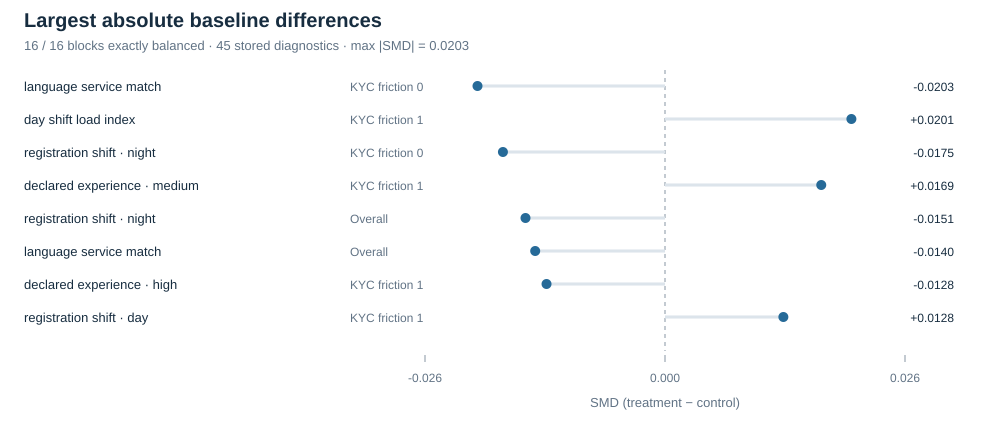

In [4]:
balance = audit["balance_diagnostics"]
baseline = record("public/baseline_balance.json")["payload"]["deterministic_result"]["balance_diagnostics"]
assert balance == baseline
blocks = counts["block_arm_counts"]
assert len(blocks) == 16 and all(b["treatment_n"] == b["control_n"] for b in blocks.values())
assert [s["scope_id"] for s in balance["scopes"]] == ["OVERALL","KYC_FRICTION_0","KYC_FRICTION_1"]
balance_rows = [{"scope":s["scope_id"],"diagnostic":d["diagnostic_id"],"smd":d["smd"],"status":d["smd_status"]}
                for s in balance["scopes"] for v in s["variables"] for d in v["diagnostics"]]
assert len(balance_rows) == 45
assert all(sum(len(v["diagnostics"]) for v in s["variables"]) == 15 for s in balance["scopes"])
finite = [r for r in balance_rows if isinstance(r["smd"],(int,float)) and math.isfinite(r["smd"])]
largest = sorted(finite,key=lambda r:abs(r["smd"]),reverse=True)[:8]
extent = max(.01, max(abs(r["smd"]) for r in largest)*1.28)
scale = lambda value: 665 + value/extent*240
parts = [text(24,27,"Largest absolute baseline differences",20,weight="bold"),
         text(24,50,f"16 / 16 blocks exactly balanced · 45 stored diagnostics · max |SMD| = {max(abs(r['smd']) for r in finite):.4f}",13,MUTED),
         line(scale(0),70,scale(0),351,GRAY,1,"4 4")]
for i,row in enumerate(largest):
    y=86+i*33
    scope={"OVERALL":"Overall","KYC_FRICTION_0":"KYC friction 0","KYC_FRICTION_1":"KYC friction 1"}[row["scope"]]
    label=row["diagnostic"].replace("__"," · ").replace("_"," ").lower()
    parts += [text(24,y+5,label,13),text(350,y+5,scope,12,MUTED),
              line(scale(0),y,scale(row["smd"]),y,GRID,3),dot(scale(row["smd"]),y),
              text(954,y+5,f"{row['smd']:+.4f}",12,anchor="end")]
for tick in (-extent,0,extent):
    parts += [line(scale(tick),355,scale(tick),362,GRAY),text(scale(tick),382,f"{tick:.3f}",12,MUTED,anchor="middle")]
parts.append(text(665,407,"SMD (treatment − control)",13,MUTED,anchor="middle"))
show_svg(parts,430,"Baseline balance","Eight largest absolute SMDs copied from the complete frozen 45-row catalogue; no decision threshold.")
if len(finite) != 45:
    show_table(["Diagnostic","Scope","Recorded status"],[(r["diagnostic"],r["scope"],r["status"]) for r in balance_rows if r not in finite])


## 5. Primary causal result
The assignment-level estimate is **+1.16 percentage points**: treatment's recorded outcome rate is **21.224%**, versus **20.064%** in control. The frozen unadjusted analysis reports a 95% CI of approximately **+0.458 to +1.862 pp**.

In this synthetic realization, assignment to neutral assistance is associated with a positive randomized ITT estimate. This does not establish real brokerage impact. The authoritative artifact retains **CALCULATION_ONLY_NO_CAUSAL_CLAIM**; no new governance claim is issued here.


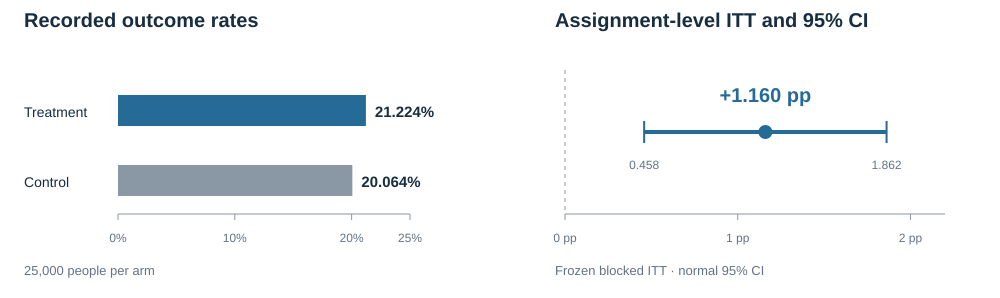

Authoritative quantity,Probability units
ITT,0.0116
Standard error,0.0035804721705631026
95% confidence interval,"[0.004582403498048364, 0.018617596501951633]"
p-value,0.0011961517507138417


In [5]:
parts = [text(24,27,"Recorded outcome rates",20,weight="bold"),
         text(555,27,"Assignment-level ITT and 95% CI",20,weight="bold")]
for i,(label,value,color) in enumerate((("Treatment",primary["mu1"],BLUE),("Control",primary["mu0"],GRAY))):
    y=95+i*70
    parts += [text(24,y+22,label,14),f'<rect x="118" y="{y}" width="{value/.25*292}" height="31" fill="{color}"/>',
              text(118+value/.25*292+9,y+22,f"{value*100:.3f}%",15,weight="bold")]
for value in (0,.1,.2,.25):
    x=118+value/.25*292
    parts += [line(x,214,x,220,GRAY),text(x,242,f"{value*100:g}%",12,MUTED,anchor="middle")]
parts += [line(118,214,410,214,GRAY),text(24,275,"25,000 people per arm",13,MUTED)]
effect_x=lambda value:565+value/.022*380
lo,hi,estimate=(primary[k] for k in ("ci_lower","ci_upper","estimate"))
parts += [line(effect_x(0),70,effect_x(0),211,GRAY,1,"4 4"),
          line(effect_x(lo),132,effect_x(hi),132,BLUE,4),
          line(effect_x(lo),121,effect_x(lo),143,BLUE,2),line(effect_x(hi),121,effect_x(hi),143,BLUE,2),
          dot(effect_x(estimate),132,BLUE,7),
          text(effect_x(estimate),102,f"+{estimate*100:.3f} pp",20,BLUE,"bold","middle"),
          text(effect_x(lo),169,f"{lo*100:.3f}",12,MUTED,"normal","middle"),
          text(effect_x(hi),169,f"{hi*100:.3f}",12,MUTED,"normal","middle")]
for value in (0,.01,.02):
    x=effect_x(value)
    parts += [line(x,214,x,220,GRAY),text(x,242,f"{value*100:g} pp",12,MUTED,anchor="middle")]
parts += [line(565,214,945,214,GRAY),text(555,275,"Frozen blocked ITT · normal 95% CI",13,MUTED)]
show_svg(parts,298,"Primary assignment-level ITT","Outcome rates and effect interval copied from primary_itt_result.json; no recalculation.")
show_table(["Authoritative quantity","Probability units"],[
    ("ITT",primary["estimate"]),("Standard error",primary["se"]),
    ("95% confidence interval",f"[{primary['ci_lower']}, {primary['ci_upper']}]"),
    ("p-value",primary["p_value"])])


## 6. Analysis freeze
**Analyst data → estimate → freeze → only then oracle unblind.**

The timestamps below are fabricated demo timestamps, but their ordering and predecessor bindings are checked against the recorded artifacts. Hashes bind the result to the exact data, specification and run that produced it. This notebook inspects that completed sequence; it does not perform another freeze or unblind.


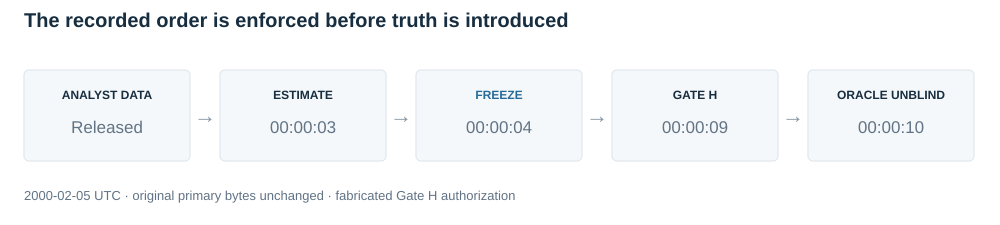

In [6]:
freeze = record("public/analysis_freeze_record.json")
approval = record("public/oracle_unblind_approval.json")
exposure = record("exposure_registry/000001.json")
primary_hash = members["public/primary_itt_result.json"]["sha256"]
freeze_hash = members["public/analysis_freeze_record.json"]["sha256"]
assert freeze["payload"]["predecessor_artifact_hashes"]["primary_itt_result.json"] == primary_hash
assert approval["payload"]["provenance"]["primary_itt_result_sha256"] == primary_hash
assert approval["payload"]["provenance"]["analysis_freeze_record_sha256"] == freeze_hash
assert exposure["payload"]["event_kind"] == "AUTHORIZED_UNBLIND"
assert primary_record["created_at_utc"] < freeze["created_at_utc"] < approval["created_at_utc"] < exposure["created_at_utc"]
assert not any(p.endswith("oracle_comparison.json") for p in read_log)
parts = [text(24,27,"The recorded order is enforced before truth is introduced",20,weight="bold")]
steps=[("ANALYST DATA","Released"),("ESTIMATE",primary_record["created_at_utc"][11:19]),
       ("FREEZE",freeze["created_at_utc"][11:19]),("GATE H",approval["created_at_utc"][11:19]),
       ("ORACLE UNBLIND",exposure["created_at_utc"][11:19])]
for i,(label,time) in enumerate(steps):
    x=24+i*196
    parts += [box(x,70,166,91),text(x+83,99,label,12,BLUE if i==2 else INK,"bold","middle"),
              text(x+83,133,time,17,MUTED,"normal","middle")]
    if i<4:parts.append(text(x+181,123,"→",22,GRAY,anchor="middle"))
parts.append(text(24,200,"2000-02-05 UTC · original primary bytes unchanged · fabricated Gate H authorization",13,MUTED))
show_svg(parts,225,"Analysis freeze before oracle access","Recorded estimate at 00:00:03, freeze at 00:00:04, Gate H at 00:00:09 and authorized unblind at 00:00:10.")


## 7. Oracle truth — introduced only after freeze evidence
**Probability-scale truth** is the expected assignment effect built into the synthetic data-generating process, averaged over these eligible clients' modeled outcome probabilities.

**Finite-schedule truth** is the exact causal effect for this realized synthetic cohort: the average contrast between its two retained potential-outcome schedules. It can differ from probability truth because the realized outcome schedule is one draw.

Only the already-authorized overall comparison is read here. No latent traits, individual potential outcomes, generator coefficients or custody payloads enter the notebook.


In [7]:
comparison_record = record("public/oracle_comparison.json")
comparison = comparison_record["payload"]["deterministic_result"]
close = record("public/benchmark_close_record.json")
binding = comparison_record["payload"]["provenance"]
assert binding["primary_itt_result_sha256"] == primary_hash
assert binding["analysis_freeze_record_sha256"] == freeze_hash
assert comparison["estimate"] == primary["estimate"]
assert comparison["unchanged_frozen_artifacts_check"] is True
assert exposure["created_at_utc"] < comparison_record["created_at_utc"] < close["created_at_utc"]
assert close["payload"]["approval_state"] == "BENCHMARK_CLOSED"
analysis_frozen_before_comparison = freeze["created_at_utc"] < comparison_record["created_at_utc"]
assert analysis_frozen_before_comparison
show_table(["Authorized overall truth","Probability units","Percentage points"],[
    ("Probability-scale truth",comparison["tau_probability_truth"],f"{comparison['tau_probability_truth']*100:+.3f} pp"),
    ("Finite-schedule truth",comparison["tau_realized_schedule_truth"],f"{comparison['tau_realized_schedule_truth']*100:+.3f} pp")],
    "Comparison recorded at 00:00:11 UTC, after the 00:00:04 analysis freeze.")


Authorized overall truth,Probability units,Percentage points
Probability-scale truth,0.013299999988454499,+1.330 pp
Finite-schedule truth,0.01318,+1.318 pp


## 8. Blind comparison
The analyst estimate was fixed before oracle truth was accessed. Both truths lie inside the recorded 95% CI; the signed errors below are copied from the authorized comparison.

**One realization does not establish estimator bias, coverage, RMSE or power.** The comparison demonstrates execution against known synthetic truth, not repeated-simulation estimator validation.


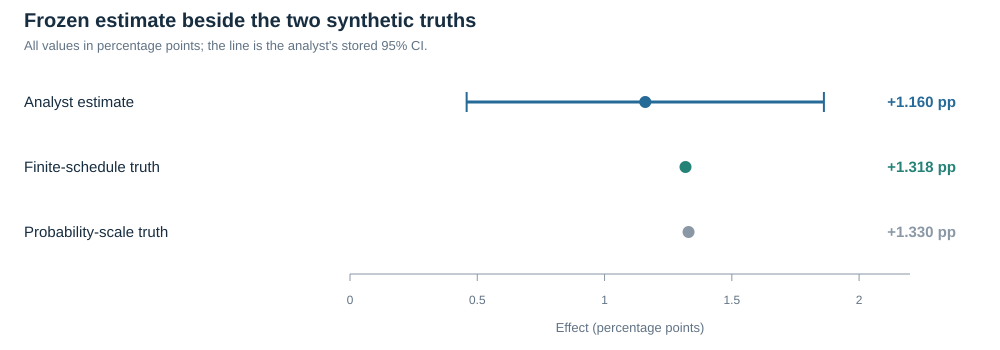

Comparison,"Stored error, displayed in pp"
Estimate − finite-schedule truth,-0.158 pp
Estimate − probability-scale truth,-0.170 pp
CI contains finite-schedule truth,True
CI contains probability-scale truth,True
Frozen before comparison,True


In [8]:
parts=[text(24,27,"Frozen estimate beside the two synthetic truths",20,weight="bold"),
       text(24,50,"All values in percentage points; the line is the analyst's stored 95% CI.",13,MUTED)]
scale=lambda v:350+v/.022*560
labels=[("Analyst estimate",comparison["estimate"],BLUE),
        ("Finite-schedule truth",comparison["tau_realized_schedule_truth"],TEAL),
        ("Probability-scale truth",comparison["tau_probability_truth"],GRAY)]
for i,(label,value,color) in enumerate(labels):
    y=102+i*65
    parts += [text(24,y+5,label,15),dot(scale(value),y,color,6),
              text(956,y+5,f"{value*100:+.3f} pp",15,color,"bold","end")]
    if i==0:
        parts += [line(scale(primary["ci_lower"]),y,scale(primary["ci_upper"]),y,BLUE,3),
                  line(scale(primary["ci_lower"]),y-10,scale(primary["ci_lower"]),y+10,BLUE,2),
                  line(scale(primary["ci_upper"]),y-10,scale(primary["ci_upper"]),y+10,BLUE,2)]
for value in (0,.005,.01,.015,.02):
    x=scale(value)
    parts += [line(x,274,x,281,GRAY),text(x,304,f"{value*100:g}",12,MUTED,anchor="middle")]
parts += [line(350,274,910,274,GRAY),text(630,332,"Effect (percentage points)",13,MUTED,anchor="middle")]
show_svg(parts,350,"Blind analyst-oracle comparison","Estimate +1.160 pp; finite truth +1.318 pp; probability truth +1.330 pp; both truths inside the stored CI.")
show_table(["Comparison","Stored error, displayed in pp"],[
    ("Estimate − finite-schedule truth",f"{comparison['estimate_minus_realized_truth']*100:+.3f} pp"),
    ("Estimate − probability-scale truth",f"{comparison['estimate_minus_probability_truth']*100:+.3f} pp"),
    ("CI contains finite-schedule truth",comparison["interval_contains_realized_truth_in_this_realization"]),
    ("CI contains probability-scale truth",comparison["interval_contains_probability_truth_in_this_realization"]),
    ("Frozen before comparison",analysis_frozen_before_comparison)])


## 9. What this project demonstrates
- A causal question translated into a randomized design and assignment-level ITT.
- Sequential customer-event semantics with a precise qualifying outcome and horizon.
- Reproducible inference, analyst/oracle separation and analysis freeze before truth access.
- Evaluation against known synthetic causal ground truth with explicit provenance.


## 10. What it does not claim
- **Not Exness data, an Exness internal process, or empirical evidence that outreach works at Exness or any broker.**
- Not production security or canonical hidden-seed acceptance.
- Not repeated-simulation estimator validation.
- No HTE, economics, policy or ML in Slice 1; no deployment recommendation.


## 11. Interview takeaway — 60 seconds
“I built a synthetic case around a concrete causal question: does assignment to neutral onboarding assistance change the chance of a first successful deposit within seven days? The design screens 55,000 people and randomizes 50,000, with exact balance within 16 blocks.

The analysis follows assignment rather than successful contact. In this public demo, the estimated effect is 1.16 percentage points, with a 95% interval of about 0.46 to 1.86 points. I freeze that result and its data/specification bindings before the oracle is accessed.

The known synthetic truths are about 1.32 and 1.33 points, both inside this interval. That demonstrates the end-to-end measurement and evaluation workflow—not real brokerage impact or validation from one simulation.”
